# Frequency of errors in the corpus

How often each error type and each error message appears in the entries, and how the retries ended. Run from this directory, it reads `../knowledge/entries`.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from pipelines_knowledge.convert import _error_key
from pipelines_watch import entries

sns.set_theme(style="whitegrid")
df = pd.DataFrame([{**e.model_dump(exclude={"snippet"}), "error": _error_key(e)}
                   for e, _ in entries.load_all("../knowledge") if e.snippet.strip()])
print(len(df), "entries,", df.error.nunique(), "distinct errors")

983 entries, 134 distinct errors


## By error type

Only the entries whose retry passed, then only those whose retry failed, most frequent type first.

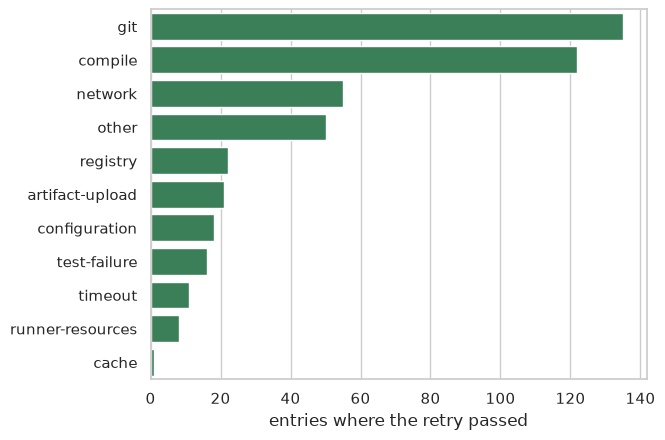

In [2]:
passed = df[df.outcome == "retry_passed"]
ax = sns.countplot(data=passed, y="error_type", order=passed.error_type.value_counts().index, color="seagreen")
ax.set(xlabel="entries where the retry passed", ylabel="")
plt.show()

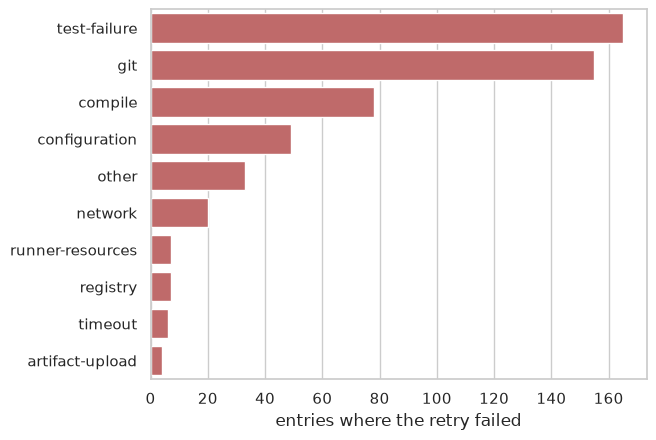

In [3]:
failed = df[df.outcome == "retry_failed"]
ax = sns.countplot(data=failed, y="error_type", order=failed.error_type.value_counts().index, color="indianred")
ax.set(xlabel="entries where the retry failed", ylabel="")
plt.show()

## Error frequency

Histogram of how many entries share the same error. Errors are matched on the first snippet line with hashes, numbers and paths blanked, the key `convert` uses for the success rate.

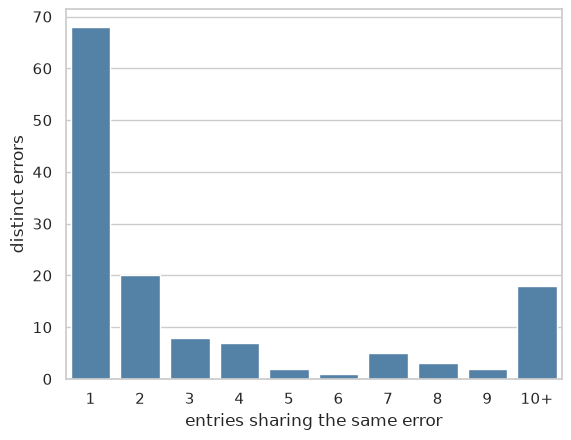

In [4]:
sizes = df.error.value_counts().clip(upper=10).value_counts().sort_index()
ax = sns.barplot(x=sizes.index.astype(str).str.replace("10", "10+"), y=sizes.values, color="steelblue")
ax.set(xlabel="entries sharing the same error", ylabel="distinct errors")
plt.show()

## Types of the errors seen only once

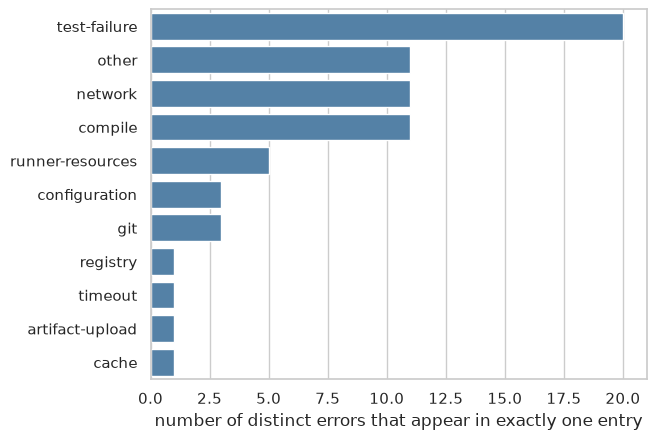

In [5]:
single = df[df.error.map(df.error.value_counts()) == 1]
ax = sns.countplot(data=single, y="error_type", order=single.error_type.value_counts().index, color="steelblue")
ax.set(xlabel="number of distinct errors that appear in exactly one entry", ylabel="")
plt.show()